In [1]:
import sys
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Python Version:", sys.version)
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("OpenCV Version:", cv2.__version__)

print("\nAll libraries imported successfully!")

Python Version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Pandas Version: 3.1.1
OpenCV Version: 5.1.0

All libraries imported successfully!


In [2]:
import os
from pathlib import Path

# Automatically identify project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "dataset" / "FER2013"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

print("Project Directory:", PROJECT_DIR)
print("Dataset Directory:", DATASET_DIR)

print("Training Folder Exists:", TRAIN_DIR.exists())
print("Testing Folder Exists:", TEST_DIR.exists())

Available GPUs: []


In [4]:
import os
from pathlib import Path

# Automatically identify project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "dataset"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

print("Project Directory:", PROJECT_DIR)
print("Dataset Directory:", DATASET_DIR)

print("Training Folder Exists:", TRAIN_DIR.exists())
print("Testing Folder Exists:", TEST_DIR.exists())

Project Directory: C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition
Dataset Directory: C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\dataset
Training Folder Exists: True
Testing Folder Exists: True


In [5]:
classes = sorted(os.listdir(TRAIN_DIR))

print("Expression Classes:")

for emotion in classes:
    print(emotion)

Expression Classes:
angry
disgust
fear
happy
neutral
sad
surprise


In [6]:
image_extensions = {'.jpg', '.jpeg', '.png'}

for split, folder in [
    ("Training", TRAIN_DIR),
    ("Testing", TEST_DIR)
]:
    print(f"\n{split} Dataset:")

    total = 0

    for emotion in sorted(os.listdir(folder)):
        emotion_path = folder / emotion

        if emotion_path.is_dir():
            count = sum(
                1 for file in emotion_path.iterdir()
                if file.suffix.lower() in image_extensions
            )

            print(f"{emotion}: {count}")
            total += count

    print("Total Images:", total)


Training Dataset:
angry: 3995
disgust: 436
fear: 4097
happy: 7215
neutral: 4965
sad: 4830
surprise: 3171
Total Images: 28709

Testing Dataset:
angry: 958
disgust: 111
fear: 1024
happy: 1774
neutral: 1233
sad: 1247
surprise: 831
Total Images: 7178


In [7]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from pathlib import Path
from PIL import Image

# Dataset paths
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = PROJECT_DIR / "dataset"

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Seven expression classes
classes = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]

print("Dataset:", DATASET_DIR)
print("Training path exists:", TRAIN_DIR.exists())
print("Testing path exists:", TEST_DIR.exists())

Dataset: C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\dataset
Training path exists: True
Testing path exists: True


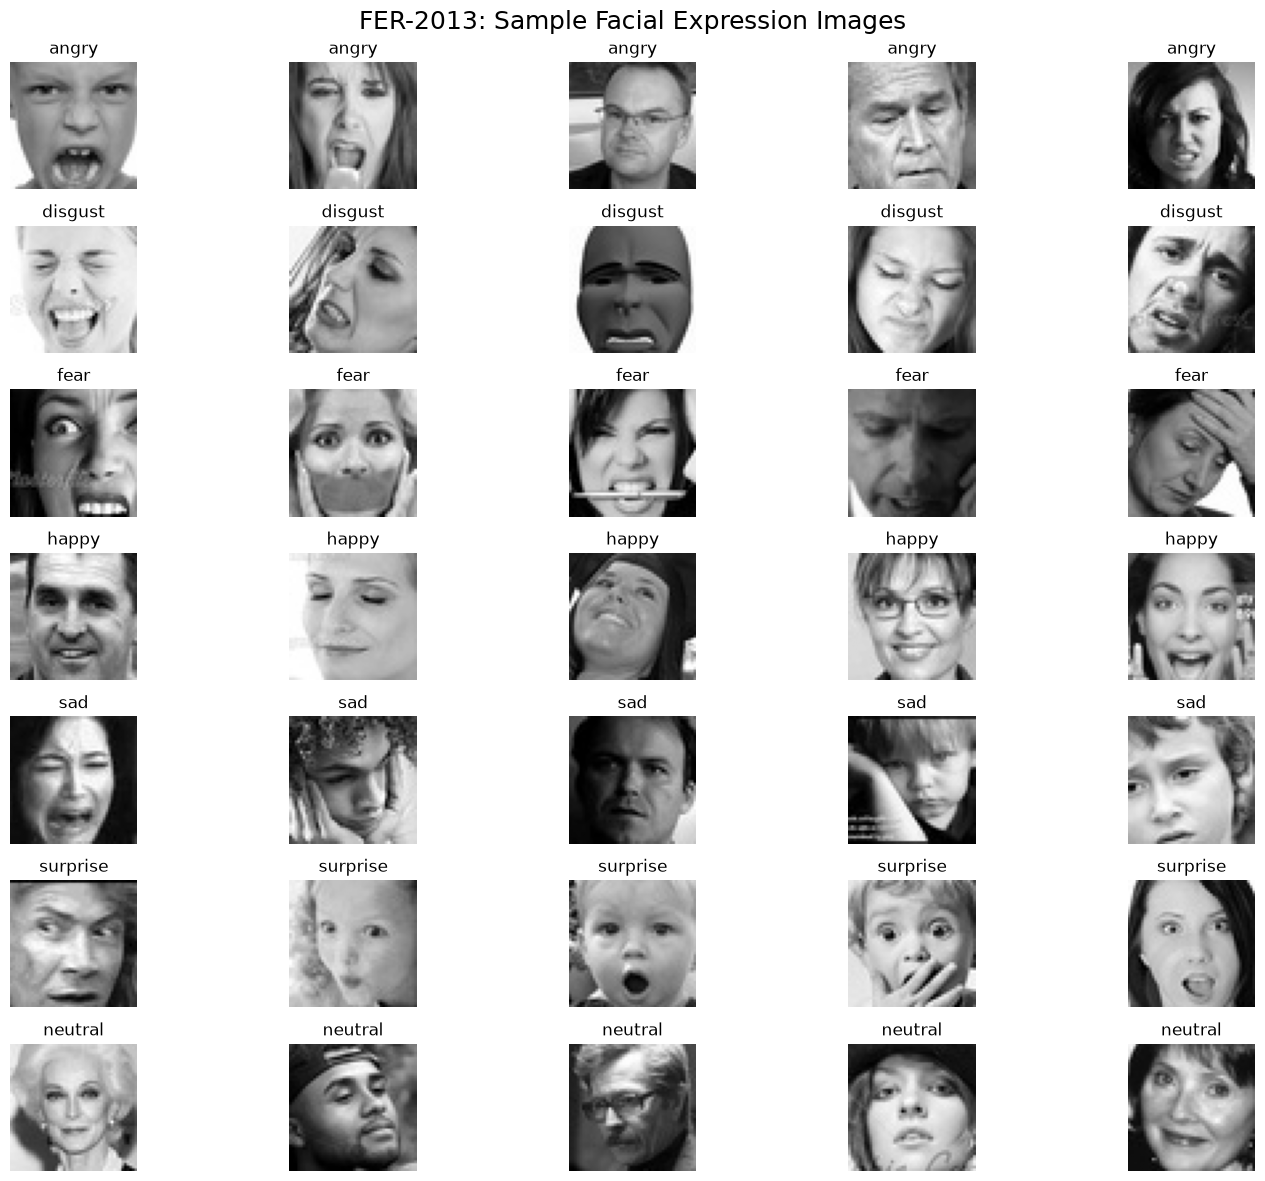

In [8]:
plt.figure(figsize=(15, 12))

for row, emotion in enumerate(classes):

    emotion_folder = TRAIN_DIR / emotion

    image_files = list(emotion_folder.glob("*.jpg"))

    selected_images = random.sample(
        image_files,
        min(5, len(image_files))
    )

    for col, image_path in enumerate(selected_images):

        img = Image.open(image_path).convert("L")

        plt.subplot(7, 5, row * 5 + col + 1)

        plt.imshow(img, cmap="gray")
        plt.title(emotion)
        plt.axis("off")

plt.suptitle(
    "FER-2013: Sample Facial Expression Images",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [9]:
sample_path = next((TRAIN_DIR / "happy").glob("*.jpg"))

sample_image = Image.open(sample_path)

print("Image Size:", sample_image.size)
print("Image Mode:", sample_image.mode)
print("Image Format:", sample_image.format)

image_array = np.array(sample_image.convert("L"))

print("Array Shape:", image_array.shape)
print("Data Type:", image_array.dtype)

Image Size: (48, 48)
Image Mode: L
Image Format: JPEG
Array Shape: (48, 48)
Data Type: uint8


Minimum Pixel Value: 0
Maximum Pixel Value: 255
Mean Pixel Value: 78.96571180555556


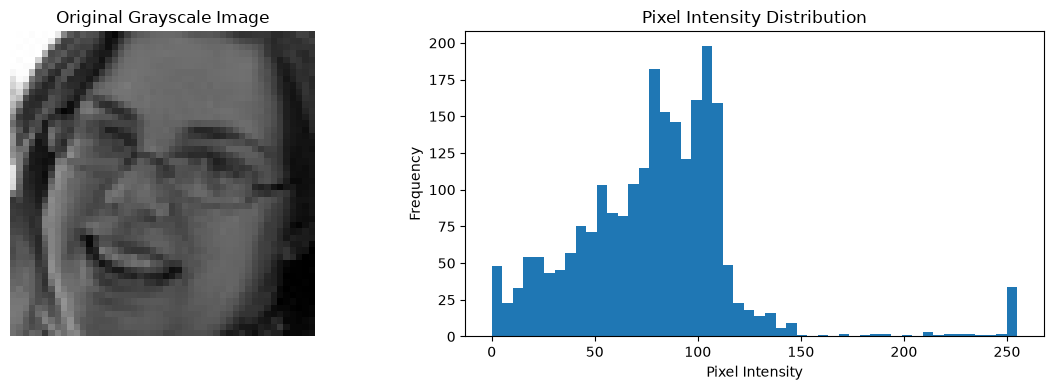

In [10]:
print("Minimum Pixel Value:", image_array.min())
print("Maximum Pixel Value:", image_array.max())
print("Mean Pixel Value:", image_array.mean())

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(image_array.flatten(), bins=50)
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

    Emotion  Image_Count
0     angry         3995
1   disgust          436
2      fear         4097
3     happy         7215
4       sad         4830
5  surprise         3171
6   neutral         4965


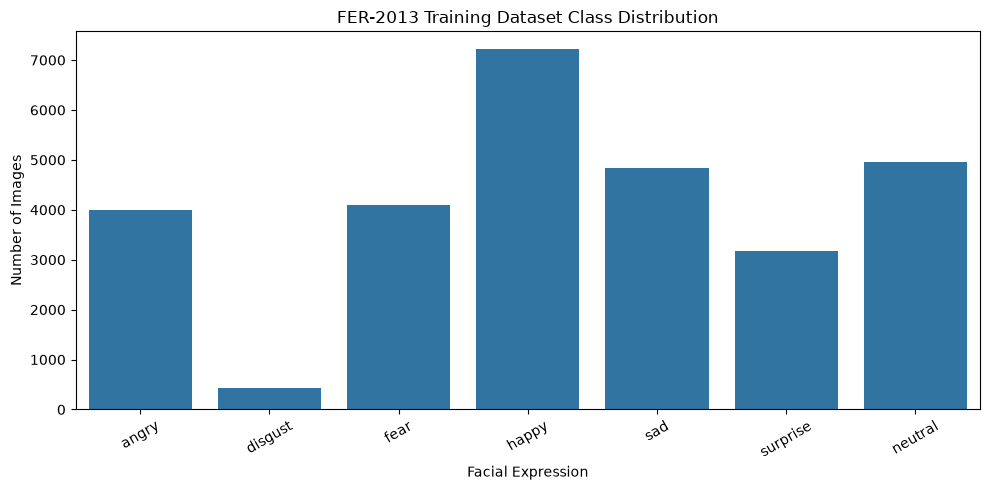

In [11]:
# Count training images
class_counts = {}

for emotion in classes:

    folder = TRAIN_DIR / emotion

    image_count = len(list(folder.glob("*.jpg")))

    class_counts[emotion] = image_count

# Convert to DataFrame
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Emotion", "Image_Count"]
)

print(df)

# Plot distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Emotion",
    y="Image_Count"
)

plt.title("FER-2013 Training Dataset Class Distribution")
plt.xlabel("Facial Expression")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig(PROJECT_DIR / "outputs" / "class_distribution.png", dpi=300)
plt.show()

In [12]:
total_images = sum(class_counts.values())

for emotion, count in class_counts.items():

    percentage = (count / total_images) * 100

    print(
        f"{emotion.capitalize():10s}: "
        f"{count:5d} images | {percentage:.2f}%"
    )

Angry     :  3995 images | 13.92%
Disgust   :   436 images | 1.52%
Fear      :  4097 images | 14.27%
Happy     :  7215 images | 25.13%
Sad       :  4830 images | 16.82%
Surprise  :  3171 images | 11.05%
Neutral   :  4965 images | 17.29%


In [13]:
largest_class = max(class_counts.values())
smallest_class = min(class_counts.values())

imbalance_ratio = largest_class / smallest_class

print("Largest Class:", largest_class)
print("Smallest Class:", smallest_class)

print("Class Imbalance Ratio:", round(imbalance_ratio, 2))

Largest Class: 7215
Smallest Class: 436
Class Imbalance Ratio: 16.55


In [16]:
import random
from PIL import Image

# Check 100 images from each class
for emotion in classes:

    folder = TRAIN_DIR / emotion

    image_files = list(folder.glob("*.jpg"))

    samples = random.sample(
        image_files,
        min(100, len(image_files))
    )

    for image_path in samples:

        with Image.open(image_path) as img:

            if img.size != (48, 48):
                print("Unexpected dimensions:", image_path, img.size)

print("Sample dimension verification completed!")

Sample dimension verification completed!


In [17]:
import tensorflow as tf
import numpy as np

IMAGE_SIZE = (48, 48)
BATCH_SIZE = 64
SEED = 42

# Load training dataset
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    validation_split=0.2,
    subset="training",
    seed=SEED,
    shuffle=True
)

# Load validation dataset
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    shuffle=True
)

# Get class names
class_names = train_ds_raw.class_names

print("Expression Classes:", class_names)
print("Number of Classes:", len(class_names))

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Expression Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of Classes: 7


In [18]:
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=False
)

print("Test dataset loaded successfully!")

Found 7178 files belonging to 7 classes.
Test dataset loaded successfully!


In [19]:
images, labels = next(iter(train_ds_raw))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (64, 48, 48, 1)
Label batch shape: (64,)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [20]:
# Normalize training, validation and testing images

def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels


train_ds = train_ds_raw.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds_raw.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds_raw.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Optimize data loading
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Normalization completed!")

Normalization completed!


In [21]:
images, labels = next(iter(train_ds))

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("Image shape:", images.shape)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Image shape: (64, 48, 48, 1)


In [22]:
for index, emotion in enumerate(class_names):
    print(index, ":", emotion)

0 : angry
1 : disgust
2 : fear
3 : happy
4 : neutral
5 : sad
6 : surprise


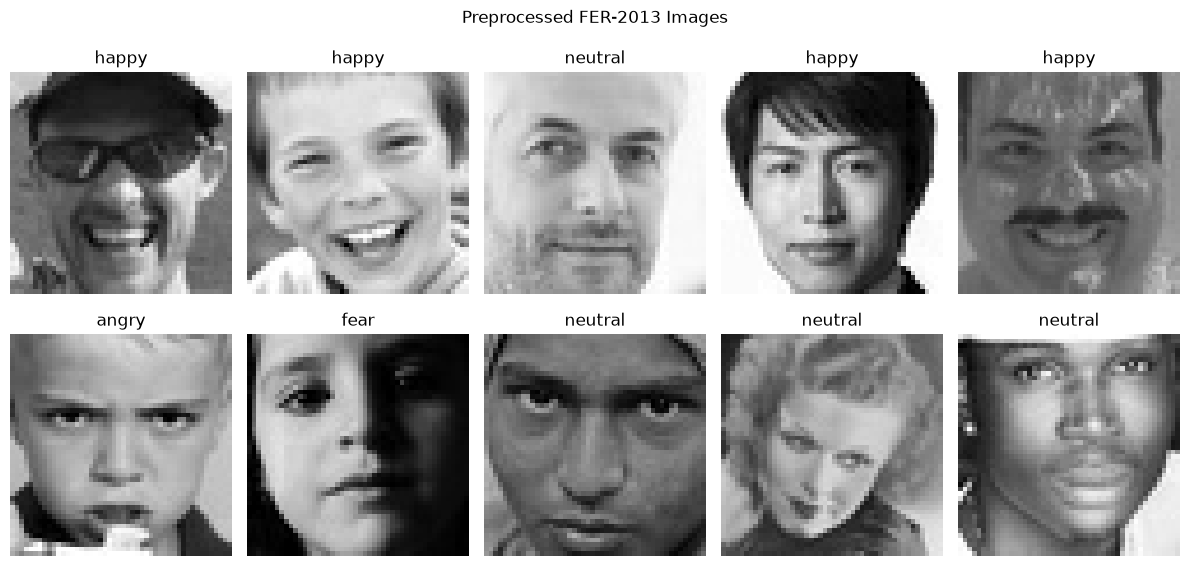

In [23]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        images[i].numpy().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.suptitle("Preprocessed FER-2013 Images")
plt.tight_layout()
plt.show()

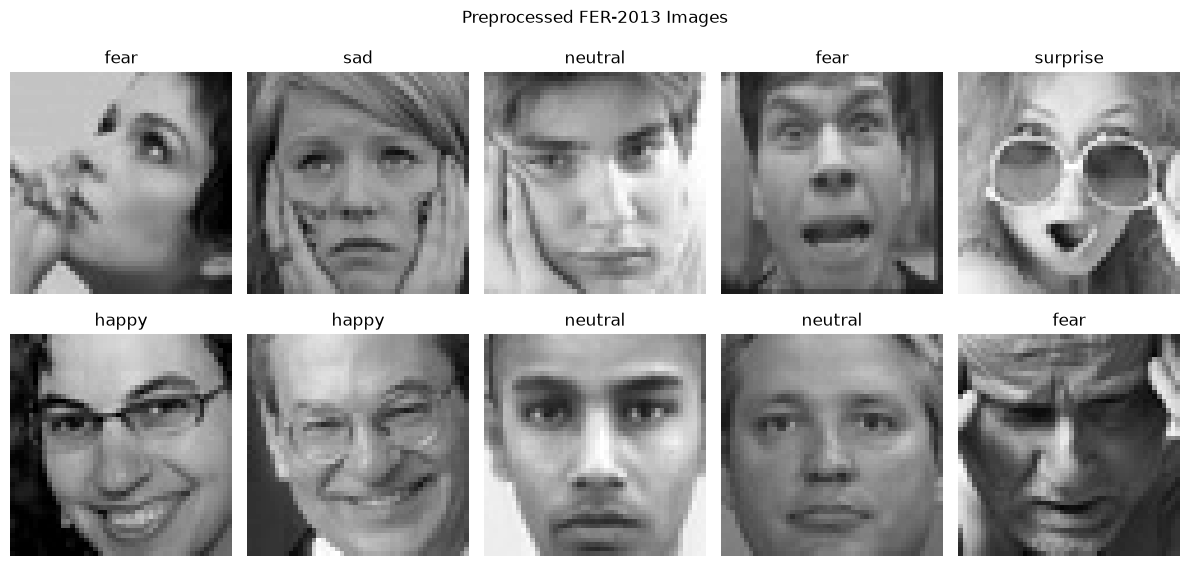

In [26]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        images[i].numpy().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.suptitle("Preprocessed FER-2013 Images")
plt.tight_layout()
plt.show()

# Data Augmentation

In [27]:
import tensorflow as tf
from tensorflow.keras import layers, models

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

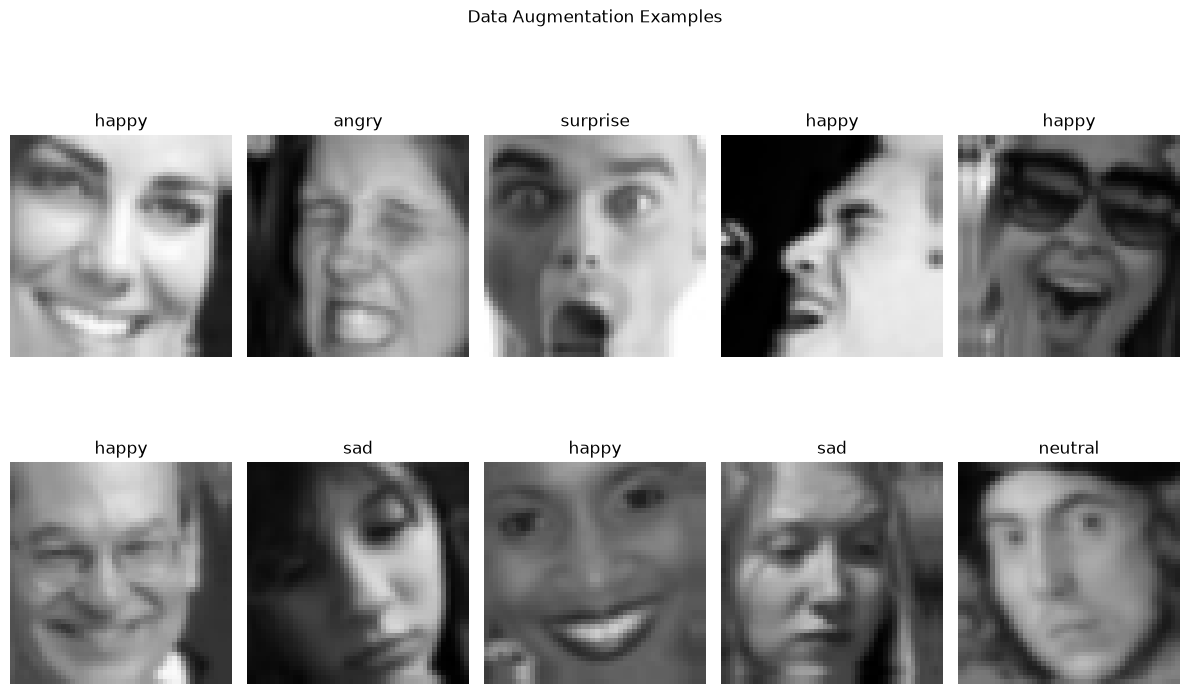

In [28]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(10):

    augmented_image = data_augmentation(
        images[i:i+1],
        training=True
    )

    plt.subplot(2, 5, i+1)

    plt.imshow(
        augmented_image[0].numpy().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.suptitle("Data Augmentation Examples")
plt.tight_layout()
plt.show()

In [29]:
from tensorflow.keras import layers, models

# Build CNN model
model = models.Sequential([

    # Input layer
    layers.Input(shape=(48, 48, 1)),

    # Data augmentation
    data_augmentation,

    # First Convolution Block
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Second Convolution Block
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Third Convolution Block
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Classification layers
    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Seven expression classes
    layers.Dense(7, activation="softmax")

])

print("CNN model created successfully!")

CNN model created successfully!


In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 878,631 (3.35 MB)

 Trainable params: 877,735 (3.35 MB)

 Non-trainable params: 896 (3.50 KB)

In [31]:
print("Total Parameters:", model.count_params())
print("Number of Output Classes:", model.output_shape[-1])

Total Parameters: 878631
Number of Output Classes: 7


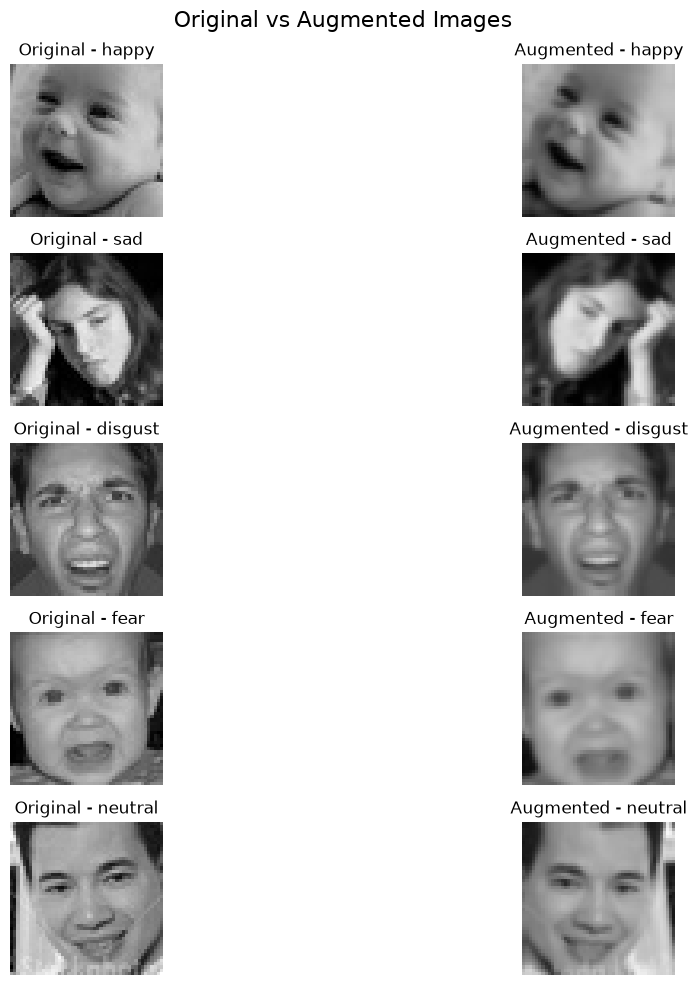

In [32]:
# Get one batch of original images
images, labels = next(iter(train_ds))

plt.figure(figsize=(14, 10))

for i in range(5):

    # Original image
    original = images[i].numpy().squeeze()

    # Generate augmented version of the SAME image
    augmented = data_augmentation(
        images[i:i+1],
        training=True
    )[0].numpy().squeeze()

    # Original
    plt.subplot(5, 2, 2*i + 1)
    plt.imshow(original, cmap="gray", vmin=0, vmax=1)
    plt.title("Original - " + class_names[labels[i].numpy()])
    plt.axis("off")

    # Augmented
    plt.subplot(5, 2, 2*i + 2)
    plt.imshow(augmented, cmap="gray", vmin=0, vmax=1)
    plt.title("Augmented - " + class_names[labels[i].numpy()])
    plt.axis("off")

plt.suptitle("Original vs Augmented Images", fontsize=16)
plt.tight_layout()
plt.show()

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [35]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [36]:
import os

os.makedirs(PROJECT_DIR / "models", exist_ok=True)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(PROJECT_DIR / "models" / "best_fer_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [37]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

In [38]:
callbacks = [
    early_stopping,
    checkpoint,
    reduce_lr
]

print("Training callbacks configured!")

Training callbacks configured!


In [39]:
EPOCHS = 25

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/25


C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.2277 - loss: 1.9193
Epoch 1: val_loss improved from None to 1.81790, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 199s 534ms/step - accuracy: 0.2277 - loss: 1.9193 - val_accuracy: 0.2442 - val_loss: 1.8179 - learning_rate: 0.0010
Epoch 2/25
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.2531 - loss: 1.8199
Epoch 2: val_loss improved from 1.81790 to 1.78252, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model.keras

Epoch 2: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model.k

In [40]:
print("Epochs Completed:", len(history.history["loss"]))

print("Best Training Accuracy:",
      max(history.history["accuracy"]) * 100)

print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]) * 100)

print("Lowest Validation Loss:",
      min(history.history["val_loss"]))

print("Final Training Accuracy:",
      history.history["accuracy"][-1] * 100)

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1] * 100)

Epochs Completed: 25
Best Training Accuracy: 31.9836288690567
Best Validation Accuracy: 36.09127402305603
Lowest Validation Loss: 1.536928415298462
Final Training Accuracy: 31.822535395622253
Final Validation Accuracy: 35.742902755737305


In [41]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

MODEL_PATH = PROJECT_DIR / "models" / "best_fer_model.keras"

best_model = tf.keras.models.load_model(MODEL_PATH)

print("Best model loaded successfully!")

Best model loaded successfully!


In [42]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nTEST RESULTS")
print("---------------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 26s 199ms/step - accuracy: 0.3626 - loss: 1.5357

TEST RESULTS
---------------------------
Test Loss: 1.5357
Test Accuracy: 36.26%


In [43]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total Test Images:", len(y_true))
print("Total Predictions:", len(y_pred))

Total Test Images: 7178
Total Predictions: 7178


In [44]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

       angry     0.0000    0.0000    0.0000       958
     disgust     0.0000    0.0000    0.0000       111
        fear     0.0000    0.0000    0.0000      1024
       happy     0.7546    0.8478    0.7985      1774
     neutral     0.2056    0.0779    0.1129      1233
         sad     0.2126    0.8043    0.3363      1247
    surprise     0.0000    0.0000    0.0000       831

    accuracy                         0.3626      7178
   macro avg     0.1675    0.2471    0.1782      7178
weighted avg     0.2587    0.3626    0.2752      7178



C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill

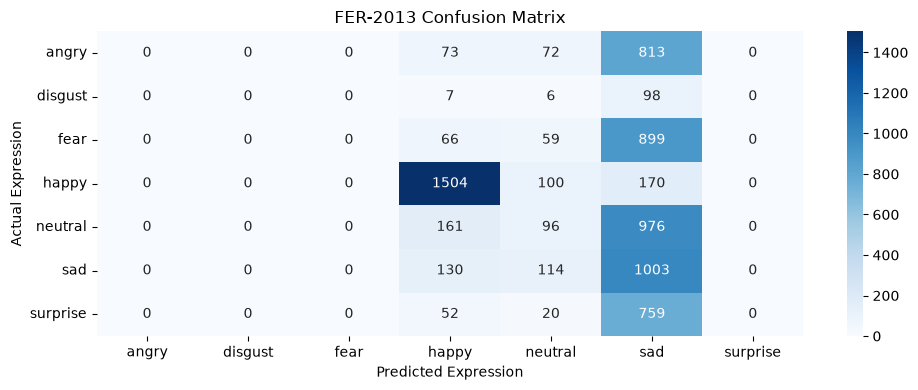

In [47]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("FER-2013 Confusion Matrix")
plt.xlabel("Predicted Expression")
plt.ylabel("Actual Expression")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs" / "confusion_matrix.png",
    dpi=300
)

plt.show()

In [46]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

report_path = PROJECT_DIR / "outputs" / "classification_report.txt"

with open(report_path, "w") as f:
    f.write(report)

print("Classification report saved!")

Classification report saved!


C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill

In [48]:
print("CLASS MAPPING")
for i, name in enumerate(class_names):
    print(i, ":", name)

print("\nTRAINING DATA DISTRIBUTION")

train_counts = np.zeros(7, dtype=int)

for images, labels in train_ds:
    train_counts += np.bincount(
        labels.numpy(),
        minlength=7
    )

for i, name in enumerate(class_names):
    print(f"{name}: {train_counts[i]}")

print("\nTEST DATA DISTRIBUTION")

test_counts = np.bincount(y_true, minlength=7)

for i, name in enumerate(class_names):
    print(f"{name}: {test_counts[i]}")

CLASS MAPPING
0 : angry
1 : disgust
2 : fear
3 : happy
4 : neutral
5 : sad
6 : surprise

TRAINING DATA DISTRIBUTION
angry: 3218
disgust: 363
fear: 3285
happy: 5813
neutral: 3965
sad: 3834
surprise: 2490

TEST DATA DISTRIBUTION
angry: 958
disgust: 111
fear: 1024
happy: 1774
neutral: 1233
sad: 1247
surprise: 831


In [49]:
print("PREDICTED CLASS DISTRIBUTION")

prediction_counts = np.bincount(y_pred, minlength=7)

for i, name in enumerate(class_names):
    print(f"{name}: {prediction_counts[i]}")

PREDICTED CLASS DISTRIBUTION
angry: 0
disgust: 0
fear: 0
happy: 1993
neutral: 467
sad: 4718
surprise: 0


In [50]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Extract training labels
train_labels = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
])

# Calculate balanced class weights
classes = np.arange(7)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    int(i): float(weight)
    for i, weight in zip(classes, weights)
}

print("CALCULATED CLASS WEIGHTS")
print("------------------------")

for i, name in enumerate(class_names):
    print(f"{name:10s}: {class_weights[i]:.4f}")

CALCULATED CLASS WEIGHTS
------------------------
angry     : 1.0196
disgust   : 9.0390
fear      : 0.9988
happy     : 0.5644
neutral   : 0.8275
sad       : 0.8558
surprise  : 1.3177


In [51]:
# Create a fresh model with the same architecture
# This does NOT copy the trained weights.

model_v2 = tf.keras.models.clone_model(model)

# Compile from scratch
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Version 2 created successfully!")

CNN Version 2 created successfully!


In [52]:
early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

checkpoint_v2 = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        PROJECT_DIR / "models" / "best_fer_model_v2.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr_v2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks_v2 = [
    early_stopping_v2,
    checkpoint_v2,
    reduce_lr_v2
]

In [53]:
EPOCHS = 25

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_v2
)

C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/25
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 652ms/step - accuracy: 0.1501 - loss: 2.0030
Epoch 1: val_loss improved from None to 1.94625, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model_v2.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_model_v2.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 272s 696ms/step - accuracy: 0.1501 - loss: 2.0030 - val_accuracy: 0.1186 - val_loss: 1.9463 - learning_rate: 5.0000e-04
Epoch 2/25
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 638ms/step - accuracy: 0.1475 - loss: 1.9466
Epoch 2: val_loss did not improve from 1.94625
359/359 ━━━━━━━━━━━━━━━━━━━━ 244s 679ms/step - accuracy: 0.1475 - loss: 1.9466 - val_accuracy: 0.1186 - val_loss: 1.9464 - learning_rate: 5.0000e-04
Epoch 3/25
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 624ms/step - accuracy: 0.1435 - loss: 1.9461
Epoch 3: val_loss did not improve from 


KeyboardInterrupt



In [54]:

# DIAGNOSTIC 1: Verify labels and class distribution

unique_labels, counts = np.unique(
    train_labels,
    return_counts=True
)

print("CLASS NAMES:", class_names)
print("\nACTUAL LABEL DISTRIBUTION")

for label, count in zip(unique_labels, counts):
    print(
        f"Label {label} ({class_names[label]}): "
        f"{count} images"
    )

print("\nCLASS WEIGHTS")

for i in range(7):
    print(f"{class_names[i]}: {class_weights[i]:.4f}")

print("\nLABEL VALIDATION")
print("Label dtype:", train_labels.dtype)
print("Unique labels:", unique_labels)
print("Number of classes:", len(unique_labels))


CLASS NAMES: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

ACTUAL LABEL DISTRIBUTION
Label 0 (angry): 3218 images
Label 1 (disgust): 363 images
Label 2 (fear): 3285 images
Label 3 (happy): 5813 images
Label 4 (neutral): 3965 images
Label 5 (sad): 3834 images
Label 6 (surprise): 2490 images

CLASS WEIGHTS
angry: 1.0196
disgust: 9.0390
fear: 0.9988
happy: 0.5644
neutral: 0.8275
sad: 0.8558
surprise: 1.3177

LABEL VALIDATION
Label dtype: int32
Unique labels: [0 1 2 3 4 5 6]
Number of classes: 7


In [55]:

# DIAGNOSTIC 2: Check model predictions

for images, labels in val_ds.take(1):

    predictions = model_v2.predict(images, verbose=0)

    predicted_classes = np.argmax(
        predictions, axis=1
    )

    actual_classes = labels.numpy()

    print("PREDICTED CLASS DISTRIBUTION")

    unique, counts = np.unique(
        predicted_classes,
        return_counts=True
    )

    for i in range(7):
        count = counts[unique.tolist().index(i)] \
            if i in unique else 0

        print(f"{class_names[i]}: {count}")

    print("\nPREDICTION PROBABILITIES")
    print(predictions[:5])


PREDICTED CLASS DISTRIBUTION
angry: 0
disgust: 0
fear: 0
happy: 0
neutral: 0
sad: 0
surprise: 64

PREDICTION PROBABILITIES
[[0.14285229 0.14296915 0.14278324 0.14284019 0.14289165 0.14263934
  0.1430242 ]
 [0.14285229 0.14296915 0.14278324 0.14284019 0.14289165 0.14263934
  0.1430242 ]
 [0.14285229 0.14296915 0.14278324 0.14284019 0.14289165 0.14263934
  0.1430242 ]
 [0.14285229 0.14296915 0.14278324 0.14284019 0.14289165 0.14263934
  0.1430242 ]
 [0.14285229 0.14296915 0.14278324 0.14284019 0.14289165 0.14263934
  0.1430242 ]]


In [56]:

for name, dataset in [
    ("TRAIN", train_ds),
    ("VALIDATION", val_ds)
]:
    images, labels = next(iter(dataset))

    print(f"\n{name} DATASET")
    print("Shape:", images.shape)
    print("Minimum:", tf.reduce_min(images).numpy())
    print("Maximum:", tf.reduce_max(images).numpy())
    print("Mean:", tf.reduce_mean(images).numpy())
    print("Standard deviation:", tf.math.reduce_std(images).numpy())



TRAIN DATASET
Shape: (64, 48, 48, 1)
Minimum: 0.0
Maximum: 1.0
Mean: 0.5213986
Standard deviation: 0.25619557

VALIDATION DATASET
Shape: (64, 48, 48, 1)
Minimum: 0.0
Maximum: 1.0
Mean: 0.5096388
Standard deviation: 0.25536788


In [57]:

images, labels = next(iter(val_ds))

predictions = model_v2.predict(images, verbose=0)

print("Prediction standard deviation:",
      np.std(predictions))

print("Prediction range:",
      np.min(predictions),
      np.max(predictions))

print("First 10 predicted classes:")
print(np.argmax(predictions[:10], axis=1))


Prediction standard deviation: 0.000116408446
Prediction range: 0.14263934 0.1430242
First 10 predicted classes:
[6 6 6 6 6 6 6 6 6 6]


In [58]:

print("TRAINABLE LAYERS")

for layer in model_v2.layers:
    print(
        layer.name,
        "Trainable:", layer.trainable
    )

print("\nOPTIMIZER LEARNING RATE:")
print(
    tf.keras.backend.get_value(
        model_v2.optimizer.learning_rate
    )
)


TRAINABLE LAYERS
data_augmentation Trainable: True
conv2d Trainable: True
batch_normalization Trainable: True
activation Trainable: True
conv2d_1 Trainable: True
batch_normalization_1 Trainable: True
activation_1 Trainable: True
max_pooling2d Trainable: True
dropout Trainable: True
conv2d_2 Trainable: True
batch_normalization_2 Trainable: True
activation_2 Trainable: True
conv2d_3 Trainable: True
batch_normalization_3 Trainable: True
activation_3 Trainable: True
max_pooling2d_1 Trainable: True
dropout_1 Trainable: True
conv2d_4 Trainable: True
batch_normalization_4 Trainable: True
activation_4 Trainable: True
conv2d_5 Trainable: True
batch_normalization_5 Trainable: True
activation_5 Trainable: True
max_pooling2d_2 Trainable: True
dropout_2 Trainable: True
flatten Trainable: True
dense Trainable: True
dropout_3 Trainable: True
dense_1 Trainable: True

OPTIMIZER LEARNING RATE:
0.000125


In [59]:

import tensorflow as tf
import numpy as np
from pathlib import Path

# Create model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Data augmentation
# Images are already normalized to [0, 1].
# --------------------------------------------------
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")


# --------------------------------------------------
# 2. Final CNN architecture
# --------------------------------------------------
inputs = tf.keras.Input(shape=(48, 48, 1))

x = data_augmentation(inputs)

# Block 1
x = tf.keras.layers.Conv2D(
    32, (3, 3), padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D((2, 2))(x)
x = tf.keras.layers.Dropout(0.20)(x)

# Block 2
x = tf.keras.layers.Conv2D(
    64, (3, 3), padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D((2, 2))(x)
x = tf.keras.layers.Dropout(0.25)(x)

# Block 3
x = tf.keras.layers.Conv2D(
    128, (3, 3), padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D((2, 2))(x)
x = tf.keras.layers.Dropout(0.30)(x)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.50)(x)

outputs = tf.keras.layers.Dense(7, activation="softmax")(x)

final_model = tf.keras.Model(inputs, outputs, name="FER_Final_CNN")


# --------------------------------------------------
# 3. Compile
# --------------------------------------------------
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_model.summary()


Model: "FER_Final_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,759 (432.65 KB)

 Trainable params: 110,311 (430.90 KB)

 Non-trainable params: 448 (1.75 KB)

In [60]:

# Collect training labels
train_labels = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
])

classes = np.arange(7)
class_counts = np.bincount(train_labels, minlength=7)

# Square-root balanced weights
weights = np.sqrt(
    len(train_labels) / (len(classes) * class_counts)
)

# Normalize weights so their average is 1
weights = weights / np.mean(weights)

final_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class counts:", class_counts)
print("Final class weights:", final_class_weights)


Class counts: [3218  363 3285 5813 3965 3834 2490]
Final class weights: {0: 0.8078415646122331, 1: 2.4052814495610577, 2: 0.7995608618045258, 3: 0.6010616965881336, 4: 0.7277758137572091, 5: 0.7401046964404417, 6: 0.9183739172363998}


In [61]:

checkpoint_path = MODEL_DIR / "best_fer_final.keras"

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

final_callbacks = [
    early_stopping,
    reduce_lr,
    model_checkpoint
]

# FINAL TRAINING
history_final = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=final_class_weights,
    callbacks=final_callbacks
)


Epoch 1/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.2185 - loss: 1.4642
Epoch 1: val_loss improved from None to 1.86872, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_final.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_final.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 119s 301ms/step - accuracy: 0.2185 - loss: 1.4642 - val_accuracy: 0.2484 - val_loss: 1.8687 - learning_rate: 3.0000e-04
Epoch 2/40
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.2519 - loss: 1.4235
Epoch 2: val_loss improved from 1.86872 to 1.79072, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_final.keras

Epoch 2: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\b

In [62]:

best_epoch = np.argmin(history_final.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Best training accuracy:",
      max(history_final.history["accuracy"]))
print("Best validation accuracy:",
      max(history_final.history["val_accuracy"]))
print("Lowest validation loss:",
      min(history_final.history["val_loss"]))

print("Saved model:", checkpoint_path)


Best epoch: 39
Best training accuracy: 0.41344478726387024
Best validation accuracy: 0.45549556612968445
Lowest validation loss: 1.4364657402038574
Saved model: C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_final.keras


FINAL TEST ACCURACY: 46.95 %
Total test images: 7178

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

       angry       0.31      0.27      0.29       958
     disgust       0.00      0.00      0.00       111
        fear       0.27      0.11      0.15      1024
       happy       0.61      0.76      0.68      1774
     neutral       0.40      0.51      0.45      1233
         sad       0.39      0.37      0.38      1247
    surprise       0.60      0.67      0.63       831

    accuracy                           0.47      7178
   macro avg       0.37      0.38      0.37      7178
weighted avg       0.43      0.47      0.44      7178


PREDICTION COUNTS:
angry: 829
disgust: 0
fear: 422
happy: 2225
neutral: 1596
sad: 1168
surprise: 938


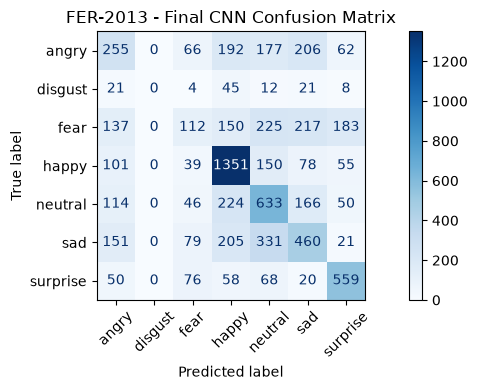

In [64]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

# Load the best saved checkpoint
best_model = tf.keras.models.load_model(
    str(checkpoint_path)
)

class_names = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

# Collect predictions and actual labels in the SAME iteration
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(probabilities, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Overall test accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print("FINAL TEST ACCURACY:", round(test_accuracy * 100, 2), "%")
print("Total test images:", len(y_true))

# Classification report
print("\nCLASSIFICATION REPORT:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(7),
    target_names=class_names,
    zero_division=0
))

# Prediction distribution
print("\nPREDICTION COUNTS:")
for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(y_pred == i)}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=np.arange(7))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 4))
display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)
plt.title("FER-2013 - Final CNN Confusion Matrix")
plt.tight_layout()
plt.show()


In [65]:

import shutil
from pathlib import Path

baseline_path = PROJECT_DIR / "models" / "best_fer_final.keras"
backup_path = PROJECT_DIR / "models" / "baseline_fer_46_95.keras"

shutil.copy2(baseline_path, backup_path)

print("Baseline backup created:", backup_path)


Baseline backup created: C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\baseline_fer_46_95.keras


In [66]:

import tensorflow as tf
import numpy as np

fine_model = tf.keras.models.load_model(
    str(baseline_path),
    compile=False
)

print("Our trained model loaded.")
fine_model.summary()


Our trained model loaded.


Model: "FER_Final_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,759 (432.65 KB)

 Trainable params: 110,311 (430.90 KB)

 Non-trainable params: 448 (1.75 KB)

In [67]:

# Collect labels from training dataset
train_labels = np.concatenate([
    labels.numpy()
    for images, labels in train_ds
]).astype(np.int32)

# Calculate square-root balanced class weights
class_counts = np.bincount(train_labels, minlength=7)

weights = np.sqrt(
    len(train_labels) / (7 * class_counts)
)

weights = weights / np.mean(weights)

print("Class counts:", class_counts)
print("Class weights:", weights)

# Convert training labels to one-hot and add sample weights
def prepare_training_data(images, labels):
    labels = tf.cast(labels, tf.int32)

    one_hot_labels = tf.one_hot(labels, depth=7)

    sample_weights = tf.gather(
        tf.constant(weights, dtype=tf.float32),
        labels
    )

    return images, one_hot_labels, sample_weights

# Validation labels: one-hot, without training sample weights
def prepare_validation_data(images, labels):
    labels = tf.cast(labels, tf.int32)
    return images, tf.one_hot(labels, depth=7)

train_ds_finetune = train_ds.map(
    prepare_training_data,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_ds_finetune = val_ds.map(
    prepare_validation_data,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

print("Fine-tuning datasets prepared.")


Class counts: [3218  363 3285 5813 3965 3834 2490]
Class weights: [0.80784156 2.40528145 0.79956086 0.6010617  0.72777581 0.7401047
 0.91837392]
Fine-tuning datasets prepared.


In [68]:

EPOCHS = 12
STEPS_PER_EPOCH = tf.data.experimental.cardinality(
    train_ds
).numpy()

total_steps = EPOCHS * STEPS_PER_EPOCH

cosine_lr = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0001,
    decay_steps=total_steps,
    alpha=0.1
)

fine_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=cosine_lr
    ),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    ),
    metrics=["accuracy"]
)

print("Fine-tuning model compiled.")


Fine-tuning model compiled.


In [69]:

fine_checkpoint = (
    PROJECT_DIR / "models" / "best_fer_improved.keras"
)

early_stop_fine = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

save_fine = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(fine_checkpoint),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history_fine = fine_model.fit(
    train_ds_finetune,
    validation_data=val_ds_finetune,
    epochs=EPOCHS,
    callbacks=[
        early_stop_fine,
        save_fine
    ]
)


Epoch 1/12


C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.4133 - loss: 1.2496
Epoch 1: val_loss improved from None to 1.49542, saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_improved.keras

Epoch 1: finished saving model to C:\Users\Chaithanya Reddy\Projects\Facial_Expression_Recognition\Facial_Expression_Recognition\models\best_fer_improved.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 84s 216ms/step - accuracy: 0.4133 - loss: 1.2496 - val_accuracy: 0.4494 - val_loss: 1.4954
Epoch 2/12
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.4159 - loss: 1.2457
Epoch 2: val_loss did not improve from 1.49542
359/359 ━━━━━━━━━━━━━━━━━━━━ 103s 286ms/step - accuracy: 0.4159 - loss: 1.2457 - val_accuracy: 0.4393 - val_loss: 1.5008
Epoch 3/12
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.4095 - loss: 1.2477
Epoch 3: val_loss improved from 1.49542 to 1.49353, saving model to C:\Users\Chaithanya Reddy\Projects\Faci

In [70]:

print("BASELINE MODEL")
print("Best validation accuracy: 45.55%")
print("Best validation loss: 1.4365")

print("\nIMPROVED MODEL")

print(
    "Best validation accuracy:",
    round(max(history_fine.history["val_accuracy"]) * 100, 2),
    "%"
)

print(
    "Best validation loss:",
    round(min(history_fine.history["val_loss"]), 4)
)


BASELINE MODEL
Best validation accuracy: 45.55%
Best validation loss: 1.4365

IMPROVED MODEL
Best validation accuracy: 46.44 %
Best validation loss: 1.477


In [71]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Load your improved model
improved_model = tf.keras.models.load_model(
    PROJECT_DIR / "models" / "best_fer_improved.keras",
    compile=False
)

# Get actual test labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict test images
y_prob = improved_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Calculate accuracy
test_accuracy = accuracy_score(y_true, y_pred)

print("Improved Model Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

# Detailed performance
class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step
Improved Model Test Accuracy: 47.35 %

Classification Report:
              precision    recall  f1-score   support

       angry       0.32      0.27      0.29       958
     disgust       0.00      0.00      0.00       111
        fear       0.27      0.13      0.18      1024
       happy       0.61      0.76      0.68      1774
     neutral       0.41      0.49      0.45      1233
         sad       0.38      0.41      0.39      1247
    surprise       0.64      0.66      0.65       831

    accuracy                           0.47      7178
   macro avg       0.38      0.39      0.38      7178
weighted avg       0.44      0.47      0.45      7178


Confusion Matrix:
[[ 259    0   85  186  162  223   43]
 [  30    0    4   39    7   23    8]
 [ 135    0  136  144  191  260  158]
 [  98    0   50 1349  142   94   41]
 [  98    0   53  221  604  213   44]
 [ 150    0   81  196  298  506   16]
 [  50    0   90   60   66   20  545]]


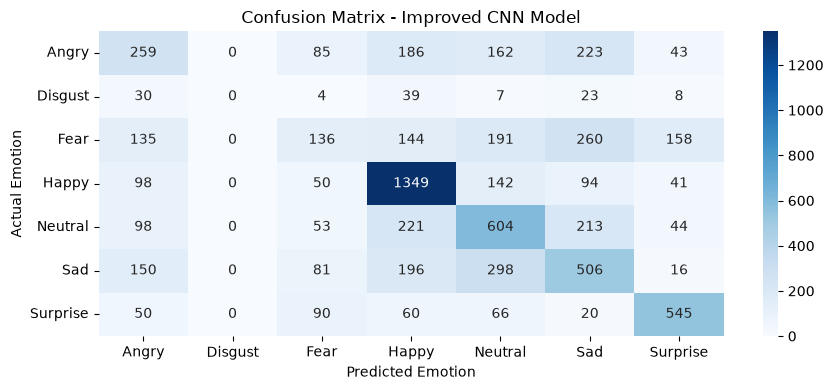

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from pathlib import Path

class_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Neutral", "Sad", "Surprise"
]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Improved CNN Model")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

# Save graph
results_dir = PROJECT_DIR / "results"
results_dir.mkdir(exist_ok=True)

plt.savefig(
    results_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

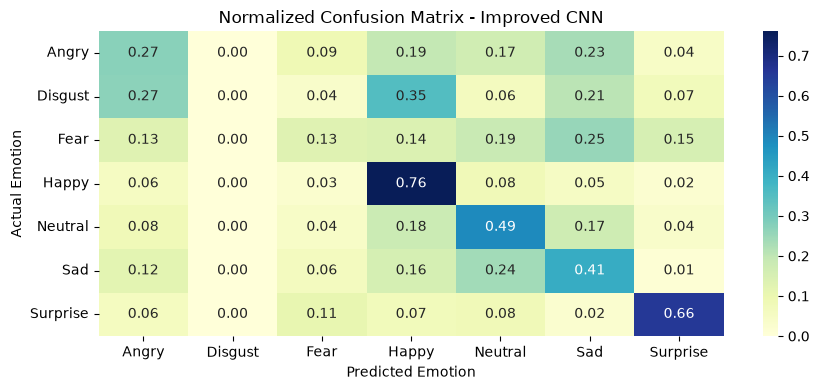

In [75]:
import numpy as np

cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 4))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix - Improved CNN")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

plt.savefig(
    results_dir / "normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

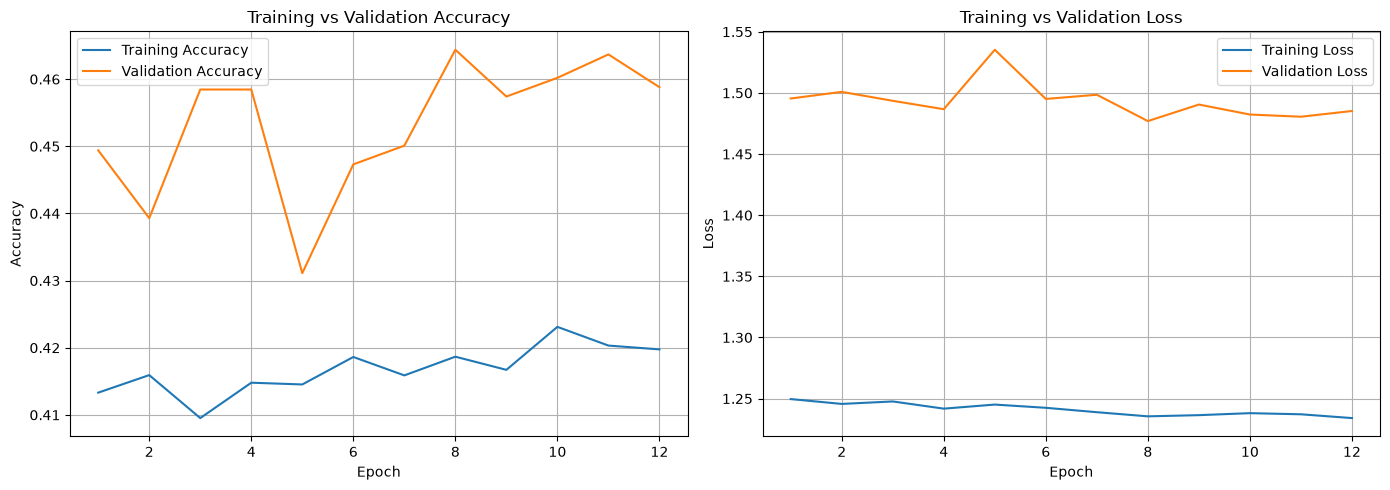

In [76]:
import matplotlib.pyplot as plt
from pathlib import Path

history_data = history_fine.history
epochs = range(1, len(history_data["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(
    epochs, history_data["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    epochs, history_data["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(
    epochs, history_data["loss"],
    label="Training Loss"
)
axes[1].plot(
    epochs, history_data["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(exist_ok=True)

plt.savefig(
    results_dir / "training_validation_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [77]:
pip install streamlit pillow tensorflow numpy

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   -------- ------------------------------- 2.4/11.2 MB 11.2 MB/s eta 0:00:01
   -------------- ------------------------- 4.2/11.2 MB 10.1 MB/s eta 0:00:01
   ----------------------- ---------------- 6.6/11.2 MB 10.9 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.2 MB 11.0 MB/s eta 0:00:01
   ---------------------------------------  11.0/11.2 MB 11.1 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 10.5 MB/s  0:00:01
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 6.9 MB/s  0:00:00
   ---------------------------------------- 0.0/29.0 MB ? eta -:--:--
   --- ------------------------------------ 2.4/29.0 MB 12.2 MB/s eta 0:00:03
   ------ --------------------------------- 4.7/29.0 MB 11.9 MB/s eta 0:00:03
   ---------- ----------------------------- 7.3/29.0 MB 11.9 MB/s eta 0:00:02
   --------